In [ ]:
# EfficientNetB0 brain-tumour classification — optimized notebook
# Run cells from top to bottom in a fresh Colab runtime.
import os, shutil, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score
)

In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("Available GPU(s):", gpus if gpus else "NONE — training will run on CPU and be much slower")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    # Mixed precision can improve throughput on supported NVIDIA GPUs.
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision enabled:", mixed_precision.global_policy())
else:
    print("Mixed precision left disabled because no GPU is visible.")

TensorFlow: 2.21.0
Available GPU(s): NONE — training will run on CPU and be much slower
Mixed precision left disabled because no GPU is visible.


In [ ]:
# Mount Drive for reading split CSVs and saving model/results.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Locate the project and dataset. Supports common folder-name variations.
MY_DRIVE = '/content/drive/MyDrive'
PROJECT_CANDIDATES = [
    os.path.join(MY_DRIVE, 'Brain_Tumor_CNN_Project'),
    os.path.join(MY_DRIVE, 'brain_tumor'),
]
PROJECT_DIR = next((p for p in PROJECT_CANDIDATES if os.path.isdir(os.path.join(p, 'results'))), None)
if PROJECT_DIR is None:
    PROJECT_DIR = next((p for p in PROJECT_CANDIDATES if os.path.isdir(p)), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not find project folder. Check the folder name under My Drive.')

RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
MODELS_DIR = MODEL_DIR  # alias used throughout this notebook
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

In [ ]:
DATASET_CANDIDATES = [
    os.path.join(PROJECT_DIR, 'dataset', 'Epic and CSCR hospital Dataset'),
    os.path.join(PROJECT_DIR, 'dataset', 'Epic and CSCR hospital Dataset-zip'),
    os.path.join(PROJECT_DIR, 'dataset'),
    os.path.join(MY_DRIVE, 'brain_tumor', 'dataset', 'Epic and CSCR hospital Dataset'),
    os.path.join(MY_DRIVE, 'brain_tumor', 'dataset', 'Epic and CSCR hospital Dataset-zip'),
]
DRIVE_DATASET_DIR = next((p for p in DATASET_CANDIDATES if os.path.isdir(os.path.join(p, 'Train')) and os.path.isdir(os.path.join(p, 'Test'))), None)
if DRIVE_DATASET_DIR is None:
    DRIVE_DATASET_DIR = next((p for p in DATASET_CANDIDATES if os.path.isdir(p) and os.path.basename(p) != 'dataset'), None)
if DRIVE_DATASET_DIR is None:
    raise FileNotFoundError('Could not locate the extracted dataset folder. Check the dataset path in Google Drive.')

In [ ]:
# Copy dataset to the runtime SSD only once. This copy disappears when the runtime resets.
LOCAL_DATASET_DIR = '/content/brain_tumor_dataset'
if os.path.abspath(DRIVE_DATASET_DIR) != os.path.abspath(LOCAL_DATASET_DIR):
    if not os.path.isdir(LOCAL_DATASET_DIR):
        print('Copying dataset to Colab local storage; first copy may take a while...')
        shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATASET_DIR)
        print('Local copy complete.')
    else:
        print('Reusing existing local dataset copy.')
DATASET_DIR = LOCAL_DATASET_DIR
print('Project:', PROJECT_DIR)
print('Dataset source:', DRIVE_DATASET_DIR)
print('Local dataset:', DATASET_DIR)
print('Results:', RESULTS_DIR)
print('Models:', MODELS_DIR)

Copying dataset to Colab local storage; first copy may take a while...
Local copy complete.
Project: /content/drive/MyDrive/Brain_Tumor_CNN_Project
Dataset source: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset
Local dataset: /content/brain_tumor_dataset
Results: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results
Models: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models


In [ ]:
# Locate split CSVs (the notebook expects pre-created train/validation/test splits).
def find_csv(candidates):
    for path in candidates:
        if os.path.isfile(path):
            return path
    return None

train_csv = find_csv([
    os.path.join(RESULTS_DIR, 'train_split.csv'),
    os.path.join(RESULTS_DIR, 'train.csv'),
])
val_csv = find_csv([
    os.path.join(RESULTS_DIR, 'validation_split.csv'),
    os.path.join(RESULTS_DIR, 'val_split.csv'),
    os.path.join(RESULTS_DIR, 'validation.csv'),
])
test_csv = find_csv([
    os.path.join(RESULTS_DIR, 'test_split.csv'),
    os.path.join(RESULTS_DIR, 'test.csv'),
])
if not all([train_csv, val_csv, test_csv]):
    raise FileNotFoundError(
        'Missing split CSV(s). Expected train_split.csv, validation_split.csv (or val_split.csv), '
        'and test_split.csv inside: ' + RESULTS_DIR
    )

In [ ]:
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    if not {'image_path', 'label'}.issubset(df.columns):
        raise ValueError(f'{name} CSV must contain columns image_path and label; found {df.columns.tolist()}')
    df['label'] = pd.to_numeric(df['label'], errors='raise').astype('int32')
    if not set(df['label'].unique()).issubset({0, 1}):
        raise ValueError(f'{name} labels must be encoded as 0 and 1 for binary classification.')

print(f'Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}')

Train: 4,844 | Validation: 1,930 | Test: 2,093


In [ ]:
# Resolve CSV image paths to the local copy where possible, then verify ALL splits.
# Relative paths are preserved; basename fallback is used only if it is unambiguous.
local_files = {}
for root, _, files in os.walk(DATASET_DIR):
    for filename in files:
        if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            local_files.setdefault(filename, []).append(os.path.join(root, filename))

source_root = os.path.abspath(DRIVE_DATASET_DIR)
local_root = os.path.abspath(DATASET_DIR)
def resolve_local_path(raw_path):
    raw_path = str(raw_path)
    if os.path.isfile(raw_path) and os.path.abspath(raw_path).startswith(local_root + os.sep):
        return raw_path
    # Map a path under the original dataset root to the same relative path locally.
    try:
        rel = os.path.relpath(os.path.abspath(raw_path), source_root)
        candidate = os.path.join(local_root, rel)
        if os.path.isfile(candidate):
            return candidate
    except Exception:
        pass
    # If the CSV uses an older project root, preserve the Train/Test/class/file suffix.
    parts = Path(raw_path).parts
    lower_parts = [part.lower() for part in parts]
    marker_idx = next((i for i, part in enumerate(lower_parts) if part in ('train', 'test', 'validation', 'val')), None)
    if marker_idx is not None:
        candidate = os.path.join(local_root, *parts[marker_idx:])
        if os.path.isfile(candidate):
            return candidate
        # Dataset may be nested one level below the copied directory.
        for nested_root, _, _ in os.walk(local_root):
            candidate = os.path.join(nested_root, *parts[marker_idx:])
            if os.path.isfile(candidate):
                return candidate
    # CSVs sometimes contain paths from an older Drive/project location.
    matches = local_files.get(os.path.basename(raw_path), [])
    if len(matches) == 1:
        return matches[0]
    # Keep original path so the validation below reports it clearly.
    return raw_path

In [ ]:
for df in (train_df, val_df, test_df):
    df['image_path'] = df['image_path'].map(resolve_local_path)

for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    missing = [p for p in df['image_path'] if not os.path.isfile(p)]
    print(f'{name}: {len(missing)} missing image path(s)')
    if missing:
        raise FileNotFoundError('Example missing image path(s):\n' + '\n'.join(map(str, missing[:5])))

CLASS_NAMES = ['Non-Tumourous', 'Tumourous']
print('Image paths verified and mapped to local storage where possible.')

train: 0 missing image path(s)
validation: 0 missing image path(s)
test: 0 missing image path(s)
Image paths verified and mapped to local storage where possible.


In [ ]:
# Fast, robust image decoding. EfficientNetB0's Keras implementation includes rescaling,
# so keep image pixels in the 0..255 range (do NOT divide by 255 here).
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=False)
    image = tf.cast(image, tf.float32)
    label = tf.cast(label, tf.float32)
    return image, label

sample_img, sample_label = preprocess_image(
    train_df.iloc[0]['image_path'], train_df.iloc[0]['label']
)
print('Processed shape:', sample_img.shape)
print('Pixel range:', float(tf.reduce_min(sample_img)), 'to', float(tf.reduce_max(sample_img)))
assert tuple(sample_img.shape) == (224, 224, 3)

Processed shape: (224, 224, 3)
Pixel range: 0.0 to 221.0


In [ ]:
# Efficient input pipeline: parallel decode/resize + prefetch. Avoid cache() by default because
# caching a large dataset in RAM can exhaust Colab memory.
def make_dataset(df, training=False):
    paths = df['image_path'].astype(str).to_numpy()
    labels = df['label'].astype('float32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(df), 2048), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(preprocess_image, num_parallel_calls=AUTOTUNE, deterministic=not training)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    return ds.prefetch(AUTOTUNE)

In [ ]:
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)
print('Batches — train:', tf.data.experimental.cardinality(train_ds).numpy(),
      'validation:', tf.data.experimental.cardinality(val_ds).numpy(),
      'test:', tf.data.experimental.cardinality(test_ds).numpy())

Batches — train: 152 validation: 61 test: 66


In [ ]:
# Sanity-check one batch before spending time training.
images_batch, labels_batch = next(iter(train_ds))
print('Image batch:', images_batch.shape, images_batch.dtype)
print('Label batch:', labels_batch.shape, labels_batch.dtype)
print('Pixel range:', float(tf.reduce_min(images_batch)), 'to', float(tf.reduce_max(images_batch)))
print('Labels in first batch:', np.unique(labels_batch.numpy()))

Image batch: (32, 224, 224, 3) <dtype: 'float32'>
Label batch: (32,) <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Labels in first batch: [0. 1.]


In [ ]:
# Class weights for imbalanced binary labels.
y_train = train_df['label'].to_numpy().astype(int)
classes = np.unique(y_train)
if not np.array_equal(classes, np.array([0, 1])):
    raise ValueError(f'Training split must contain both labels 0 and 1; found {classes}')
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = {int(label): float(weight) for label, weight in zip(classes, weights)}
print('Class weights:', class_weights)
print('Class mapping: 0 = Non-Tumourous, 1 = Tumourous (verify this matches your CSV labels).')

Class weights: {0: 3.5881481481481483, 1: 0.580954665387383}
Class mapping: 0 = Non-Tumourous, 1 = Tumourous (verify this matches your CSV labels).


In [ ]:
# Phase 1: EfficientNetB0 feature extraction. Keep the pretrained backbone frozen.
from tensorflow.keras import layers

base_model = tf.keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False
inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
model = tf.keras.Model(inputs, outputs, name='EfficientNetB0_BrainTumor')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Save models to Drive so they survive runtime resets.
print('Models will be saved to:', MODELS_DIR)

Models will be saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models


In [ ]:
# Phase 1 training: fewer initial epochs + early stopping to avoid wasted compute.
callbacks_phase1 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=1, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'efficientnet_b0_phase1.keras'),
        monitor='val_loss', save_best_only=True, verbose=1
    ),
]
start_time = time.time()
history_p1 = model.fit(
    train_ds, validation_data=val_ds, epochs=5,
    class_weight=class_weights, callbacks=callbacks_phase1, verbose=1
)
print(f'Phase 1 complete in {(time.time()-start_time)/60:.1f} minutes.')

Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6626 - loss: 0.5660 - precision: 0.9238 - recall: 0.6542
Epoch 1: val_loss improved from None to 0.27838, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnet_b0_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnet_b0_phase1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 611s 4s/step - accuracy: 0.7989 - loss: 0.4279 - precision: 0.9626 - recall: 0.7973 - val_accuracy: 0.8886 - val_loss: 0.2784 - val_precision: 0.9818 - val_recall: 0.8767 - learning_rate: 0.0010
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9002 - loss: 0.2641 - precision: 0.9840 - recall: 0.8984
Epoch 2: val_loss improved from 0.27838 to 0.19685, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnet_b0_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnet_b0_phase1.keras

In [ ]:
# Phase 2: fine-tune only the last 20 non-BatchNorm layers with a low learning rate.
# BatchNorm layers remain frozen for more stable transfer learning on smaller medical datasets.
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)
print('Trainable backbone layers:', sum(layer.trainable for layer in base_model.layers), '/', len(base_model.layers))

Trainable backbone layers: 15 / 238


In [ ]:
# Phase 2 fine-tuning: short run with early stopping. Best checkpoint is selected by validation loss.
callbacks_phase2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=1, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODELS_DIR, 'best_efficientnet_b0.keras'),
        monitor='val_loss', save_best_only=True, verbose=1
    ),
]
start_time = time.time()
history_p2 = model.fit(
    train_ds, validation_data=val_ds, epochs=3,
    class_weight=class_weights, callbacks=callbacks_phase2, verbose=1
)
print(f'Phase 2 complete in {(time.time()-start_time)/60:.1f} minutes.')

Epoch 1/3
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9576 - loss: 0.1399 - precision: 0.9881 - recall: 0.9623
Epoch 1: val_loss improved from None to 0.12467, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnet_b0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnet_b0.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 670s 4s/step - accuracy: 0.9517 - loss: 0.1454 - precision: 0.9888 - recall: 0.9547 - val_accuracy: 0.9591 - val_loss: 0.1247 - val_precision: 0.9919 - val_recall: 0.9565 - learning_rate: 1.0000e-05
Epoch 2/3
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9510 - loss: 0.1289 - precision: 0.9920 - recall: 0.9510
Epoch 2: val_loss improved from 0.12467 to 0.10204, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnet_b0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnet_b0.keras
152

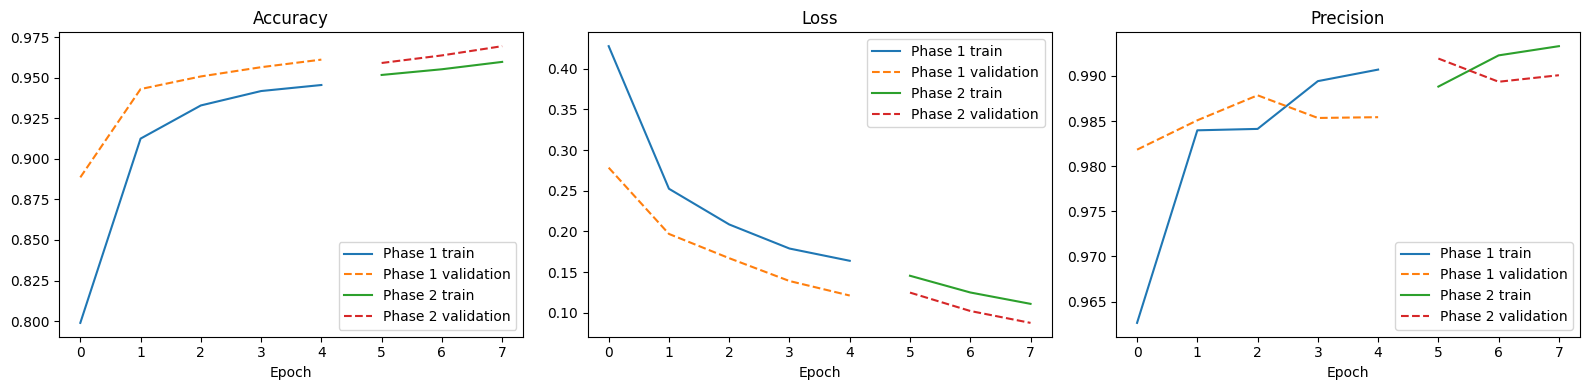

In [ ]:
# Plot combined training history.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ['accuracy', 'loss', 'precision'], ['Accuracy', 'Loss', 'Precision']):
    p1 = history_p1.history
    p2 = history_p2.history
    ax.plot(p1.get(metric, []), label='Phase 1 train')
    ax.plot(p1.get('val_' + metric, []), '--', label='Phase 1 validation')
    offset = len(p1.get(metric, []))
    ax.plot(range(offset, offset + len(p2.get(metric, []))), p2.get(metric, []), label='Phase 2 train')
    ax.plot(range(offset, offset + len(p2.get('val_' + metric, []))), p2.get('val_' + metric, []), '--', label='Phase 2 validation')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Evaluate the best saved model on the held-out test set only once.
BEST_MODEL_PATH = os.path.join(MODELS_DIR, 'best_efficientnet_b0.keras')
if not os.path.isfile(BEST_MODEL_PATH):
    # If fine-tuning did not create a checkpoint, use the phase-1 checkpoint.
    BEST_MODEL_PATH = os.path.join(MODELS_DIR, 'efficientnet_b0_phase1.keras')
if not os.path.isfile(BEST_MODEL_PATH):
    raise FileNotFoundError('No saved model checkpoint found. Run training cells first.')
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)
test_results = best_model.evaluate(test_ds, verbose=1)
test_loss, test_acc, test_prec, test_rec = test_results
print(f'\nTest loss: {test_loss:.4f} | Accuracy: {test_acc:.4f} | Precision: {test_prec:.4f} | Recall: {test_rec:.4f}')

66/66 ━━━━━━━━━━━━━━━━━━━━ 172s 3s/step - accuracy: 0.9618 - loss: 0.1236 - precision: 0.9939 - recall: 0.9589

Test loss: 0.1236 | Accuracy: 0.9618 | Precision: 0.9939 | Recall: 0.9589


66/66 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step
               precision    recall  f1-score   support

Non-Tumourous     0.8438    0.9742    0.9043       388
    Tumourous     0.9939    0.9589    0.9761      1705

     accuracy                         0.9618      2093
    macro avg     0.9188    0.9666    0.9402      2093
 weighted avg     0.9661    0.9618    0.9628      2093



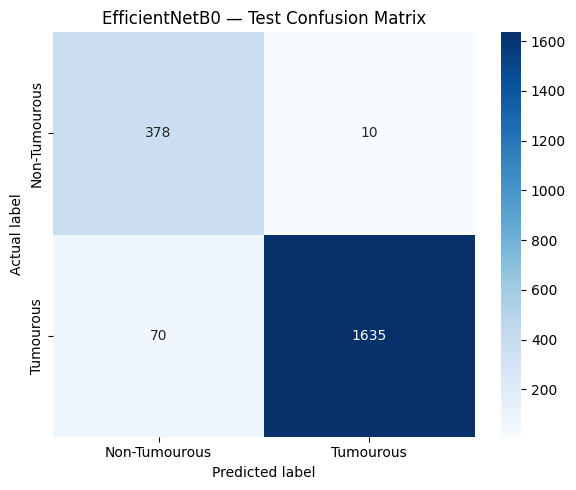

In [ ]:
# Test predictions, classification report and confusion matrix.
y_true = test_df['label'].to_numpy().astype(int)
y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('EfficientNetB0 — Test Confusion Matrix')
plt.ylabel('Actual label'); plt.xlabel('Predicted label'); plt.tight_layout(); plt.show()

In [ ]:
# Metrics table (guard divisions and single-class edge cases).
tn, fp, fn, tp = cm.ravel()
f1 = (2 * test_prec * test_rec / (test_prec + test_rec)) if (test_prec + test_rec) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0
try:
    roc_auc = roc_auc_score(y_true, y_prob)
except ValueError:
    roc_auc = np.nan
try:
    pr_auc = average_precision_score(y_true, y_prob)
except ValueError:
    pr_auc = np.nan
metrics_dict = {
    'Accuracy': test_acc, 'Tumourous Precision': test_prec,
    'Tumourous Recall': test_rec, 'Tumourous F1-score': f1,
    'Specificity': specificity, 'ROC-AUC': roc_auc, 'PR-AUC': pr_auc,
}
metrics_df = pd.DataFrame(list(metrics_dict.items()), columns=['Metric', 'Score'])
metrics_df['Score (%)'] = (metrics_df['Score'] * 100).round(2)
display(metrics_df)
metrics_df.to_csv(os.path.join(RESULTS_DIR, 'efficientnet_metrics.csv'), index=False)
print('Metrics saved to Drive.')

,Metric,Score,Score (%)
0,Accuracy,0.961777,96.18
1,Tumourous Precision,0.993921,99.39
2,Tumourous Recall,0.958944,95.89
3,Tumourous F1-score,0.976119,97.61
4,Specificity,0.974227,97.42
5,ROC-AUC,0.991219,99.12
6,PR-AUC,0.998110,99.81


Metrics saved to Drive.


In [ ]:
# Optional: print a concise classification report (uses predictions already computed above).
print('===== Classification Report =====')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

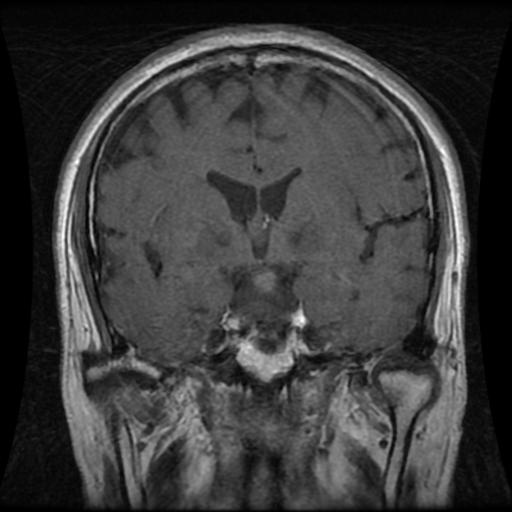

Image: 1434.jpg
Actual label: Tumourous
Predicted label: Tumourous
Tumour probability: 0.9971


In [ ]:
# Show one test example and its prediction.
from IPython.display import display
from PIL import Image
sample_row = test_df.sample(1, random_state=4).iloc[0]
display(Image.open(sample_row['image_path']).convert('RGB'))
print('Image:', os.path.basename(sample_row['image_path']))
print('Actual label:', CLASS_NAMES[int(sample_row['label'])])
print('Predicted label:', CLASS_NAMES[int(y_pred[test_df.index.get_loc(sample_row.name)])])
print('Tumour probability:', f'{float(y_prob[test_df.index.get_loc(sample_row.name)]):.4f}')

In [ ]:
# Optional comparison with a previous Custom CNN metrics file. No fabricated fallback scores.
cnn_metrics_path = os.path.join(RESULTS_DIR, 'test_metrics.csv')
comparison_df = None
if os.path.isfile(cnn_metrics_path):
    cnn_metrics = pd.read_csv(cnn_metrics_path)
    def find_metric(columns, terms):
        return next((c for c in columns if all(t in c.lower() for t in terms)), None)
    cols = list(cnn_metrics.columns)
    acc_col = find_metric(cols, ['accuracy'])
    prec_col = find_metric(cols, ['precision'])
    rec_col = find_metric(cols, ['recall'])
    f1_col = find_metric(cols, ['f1'])
    if all([acc_col, prec_col, rec_col]):
        cnn_acc = float(cnn_metrics[acc_col].iloc[0]); cnn_prec = float(cnn_metrics[prec_col].iloc[0]); cnn_rec = float(cnn_metrics[rec_col].iloc[0])
        cnn_f1 = float(cnn_metrics[f1_col].iloc[0]) if f1_col else (2*cnn_prec*cnn_rec/(cnn_prec+cnn_rec) if cnn_prec+cnn_rec else 0.0)
        # Normalize metric files that store percentages (e.g. 96.8) rather than fractions (0.968).
        if max(cnn_acc, cnn_prec, cnn_rec, cnn_f1) > 1.0:
            cnn_acc, cnn_prec, cnn_rec, cnn_f1 = [v / 100.0 for v in (cnn_acc, cnn_prec, cnn_rec, cnn_f1)]
        eff_f1 = f1
        comparison_df = pd.DataFrame({
            'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
            'Custom CNN': [cnn_acc, cnn_prec, cnn_rec, cnn_f1],
            'EfficientNetB0': [test_acc, test_prec, test_rec, eff_f1],
        })
        comparison_df['Difference (percentage points)'] = (comparison_df['EfficientNetB0'] - comparison_df['Custom CNN']) * 100
        display(comparison_df.style.format({'Difference (percentage points)': '{:+.2f}'}))
    else:
        print('CNN metrics file found, but expected accuracy/precision/recall columns were not detected.')
else:
    print('No results/test_metrics.csv found. Skipping comparison; no placeholder metrics will be used.')

In [ ]:
# Save comparison only when real Custom CNN metrics were found.
if comparison_df is not None:
    comparison_path = os.path.join(RESULTS_DIR, 'model_comparison_summary.csv')
    comparison_df.to_csv(comparison_path, index=False)
    print('Comparison report saved to:', comparison_path)
    winner = 'EfficientNetB0' if test_acc > float(comparison_df.loc[comparison_df['Metric'] == 'Accuracy', 'Custom CNN'].iloc[0]) else 'Custom CNN'
    print('Higher test accuracy in this comparison:', winner)
else:
    print('Comparison not generated because previous Custom CNN metrics were unavailable.')